# 🏋️ BÀI THỰC NGHIỆM 01: TRÍCH XUẤT KHUNG XƯƠNG (POSE ESTIMATION) VỚI MEDIAPIPE

**Học phần:** Project 3 (Đồ án 3) — SoICT, Đại học Bách khoa Hà Nội (HUST)  
**Đề tài:** Phân tích dữ liệu video và gợi ý chỉnh sửa động tác cho người tập gym  
**Mục tiêu bài thực nghiệm:**
1. Sử dụng mô hình **MediaPipe Pose Landmarker (Heavy)** bóc tách 33 khớp 3D từ video quay thực tế.
2. Trực quan hóa khung xương trên các pha động tác (Đứng thẳng $\to$ Hạ xuống $\to$ Đáy squat).
3. Đánh giá độ tin cậy bắt khớp (Visibility & Presence) và tốc độ xử lý (FPS).
4. Xuất dữ liệu chuỗi tọa độ ra file JSON phục vụ tính góc sinh cơ học ở **Tầng 2**.

## 1. Khởi tạo Môi trường & Nạp Thư viện
Nhúng module lõi `PoseEngine` từ `backend/app/core/pose.py`.

In [1]:
import sys
import json
import time
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Thêm đường dẫn backend vào sys.path
project_root = Path.cwd().parent.parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(project_root / 'backend'))

from app.core.pose import PoseEngine

print(f'📂 Thư mục gốc dự án: {project_root}')
print('✅ Nạp thư viện và module PoseEngine thành công!')

📂 Thư mục gốc dự án: D:\Project\AI_Biomechanics_Coach
✅ Nạp thư viện và module PoseEngine thành công!


## 2. Kiểm tra Mô hình Pre-trained & Danh sách Video Mẫu
Hệ thống đã chuẩn bị sẵn 2 video mẫu có góc quay và định dạng khác nhau để đối chiếu:
* **Video 1 (`sample_squat.mp4`):** Barbell Back Squat quay dọc bằng điện thoại ($608 \times 1080$, góc bên hông $90^\circ$).
* **Video 2 (`sample_squat_2.mp4`):** Bodyweight Squat quay ngang Full HD ($1920 \times 1080$, góc bên hông $90^\circ$).


In [2]:
model_path = project_root / 'ai' / 'models' / 'pretrained' / 'pose_landmarker_heavy.task'
assert model_path.exists(), f'Thiếu file model tại {model_path}'
model_size_mb = model_path.stat().st_size / (1024 * 1024)
print(f'🤖 Mô hình: {model_path.name} ({model_size_mb:.2f} MB)')

videos_dir = project_root / 'data' / 'raw' / 'squats_good'
video_files = list(videos_dir.glob('*.mp4'))

for v in video_files:
    cap = cv2.VideoCapture(str(v))
    fps = cap.get(cv2.CAP_PROP_FPS)
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    dur = total / fps if fps > 0 else 0
    print(f'📹 {v.name:20s} | Độ phân giải: {w}x{h} | FPS: {fps:.2f} | Frames: {total} | Thời lượng: {dur:.2f}s')
    cap.release()

🤖 Mô hình: pose_landmarker_heavy.task (29.24 MB)
📹 sample_squat.mp4     | Độ phân giải: 608x1080 | FPS: 29.97 | Frames: 614 | Thời lượng: 20.49s
📹 sample_squat_2.mp4   | Độ phân giải: 1920x1080 | FPS: 30.02 | Frames: 559 | Thời lượng: 18.62s


## 3. Khởi tạo PoseEngine & Chạy Trích xuất Khung xương
Chúng ta sẽ chạy trên video 1 (`sample_squat.mp4`) để bóc tách 33 khớp qua từng frame.

In [3]:
engine = PoseEngine(model_path=str(model_path))
target_video = project_root / 'data' / 'raw' / 'squats_good' / 'sample_squat.mp4'

start_time = time.time()
max_frames = 180
result = engine.extract_from_video(video_path=str(target_video), max_frames=max_frames)
elapsed = time.time() - start_time

print('=' * 50)
print('📊 KẾT QUẢ BÓC TÁCH KHUNG XƯƠNG:')
print(f'  • Tổng số frames xử lý: {result.total_frames}')
print(f'  • Số frames bắt dính người: {result.detected_frames_count}/{result.total_frames}')
print(f'  • Tỷ lệ nhận diện (Detection Rate): {result.detection_rate * 100:.2f}%')
print(f'  • Thời gian xử lý: {elapsed:.2f}s (Tốc độ ~{result.total_frames / elapsed:.1f} FPS trên CPU)')
print('=' * 50)

📊 KẾT QUẢ BÓC TÁCH KHUNG XƯƠNG:
  • Tổng số frames xử lý: 180
  • Số frames bắt dính người: 180/180
  • Tỷ lệ nhận diện (Detection Rate): 100.00%
  • Thời gian xử lý: 10.69s (Tốc độ ~16.8 FPS trên CPU)


## 4. Trực quan hóa Khung xương tại các Pha Động tác (Visualization)
Vẽ khung xương lên 3 khoảnh khắc then chốt:
1. **Pha 1 (Frame 20):** Setup / Đứng thẳng người.
2. **Pha 2 (Frame 55):** Eccentric / Đang hạ trọng tâm.
3. **Pha 3 (Frame 85):** Bottom / Xuống sâu nhất ở đáy squat.

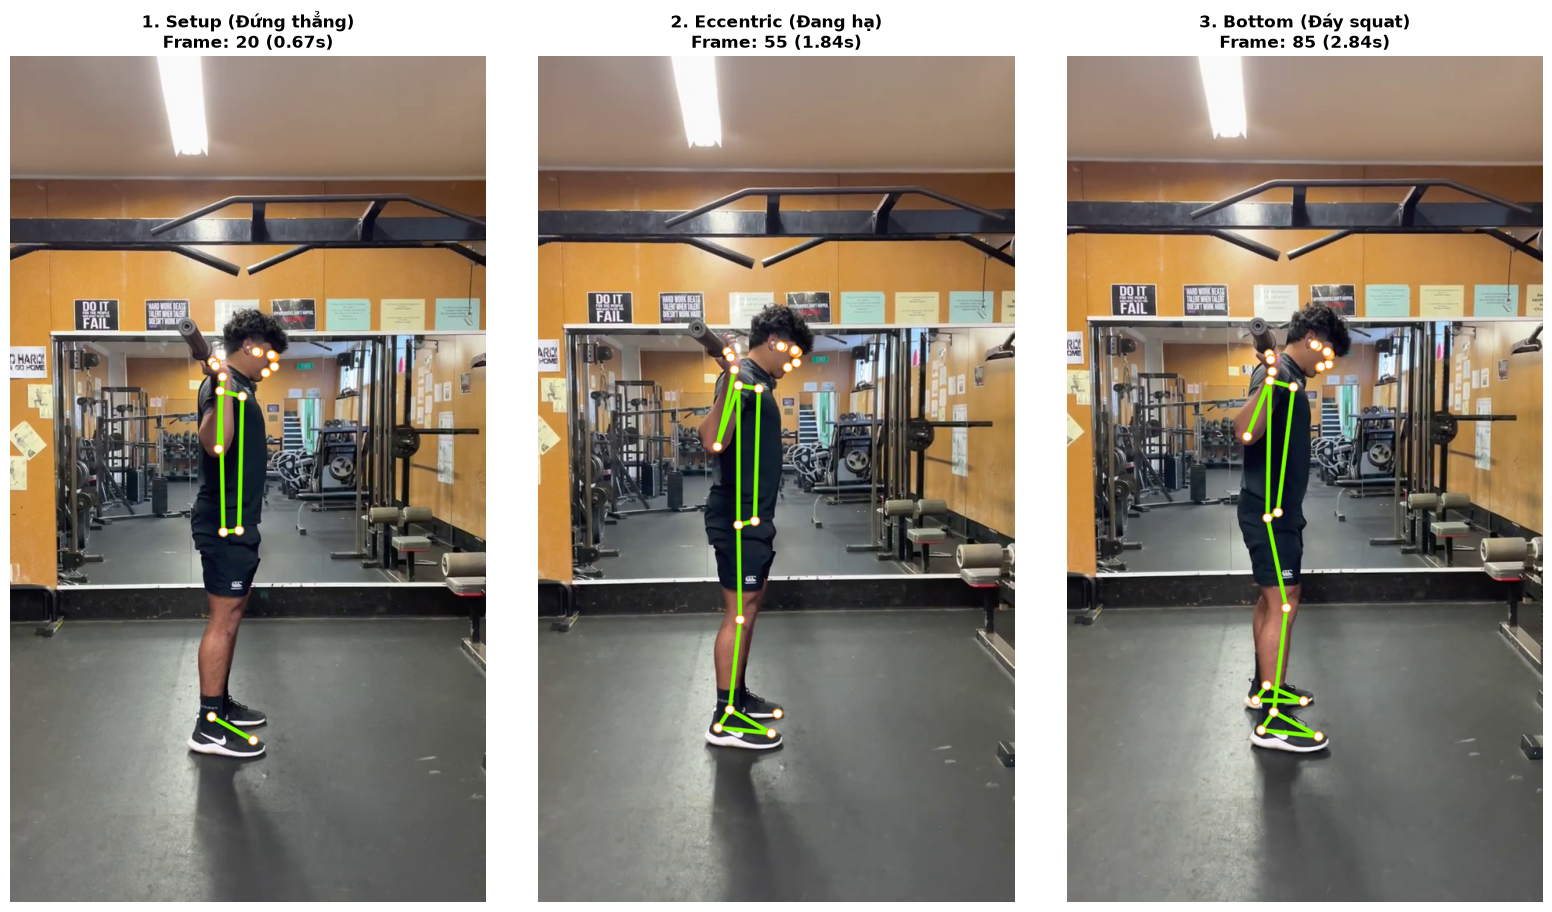

In [4]:
cap = cv2.VideoCapture(str(target_video))
frames_to_plot = [20, 55, 85]
phase_names = ['1. Setup (Đứng thẳng)', '2. Eccentric (Đang hạ)', '3. Bottom (Đáy squat)']

fig, axes = plt.subplots(1, 3, figsize=(16, 9))

for idx, (f_idx, p_name) in enumerate(zip(frames_to_plot, phase_names)):
    cap.set(cv2.CAP_PROP_POS_FRAMES, f_idx)
    ret, frame = cap.read()
    if ret and f_idx < len(result.frames):
        f_pose = result.frames[f_idx]
        if f_pose.is_detected:
            annotated = engine.draw_skeleton(frame, f_pose.landmarks, thickness=3, radius=5)
            rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(rgb)
            time_s = f_idx / result.fps
            axes[idx].set_title(f'{p_name}\nFrame: {f_idx} ({time_s:.2f}s)', fontsize=12, fontweight='bold')
            axes[idx].axis('off')

cap.release()
plt.tight_layout()
plt.show()

## 5. Phân tích Độ tin cậy (Confidence & Visibility) của các Khớp Trọng yếu
Trong phân tích bài tập Squat, 6 khớp quan trọng nhất là:
* **Khớp chi dưới:** Hông (Hip), Đầu gối (Knee), Mắt cá chân (Ankle), Gót chân (Heel).
* **Khớp thân trên:** Vai (Shoulder), Khuỷu tay (Elbow).

Chúng ta sẽ kiểm tra xem MediaPipe có nhận diện rõ ràng các khớp này xuyên suốt các frame hay không.

In [5]:
target_joints = ['left_hip', 'left_knee', 'left_ankle', 'left_heel', 'left_shoulder', 'left_foot_index']
vis_stats = {j: [] for j in target_joints}

for f in result.frames:
    if f.is_detected:
        for j_name in target_joints:
            lm = f.get_landmark(j_name)
            if lm:
                vis_stats[j_name].append(lm['visibility'])

print('📈 ĐỘ TIN CẬY TRUNG BÌNH CỦA CÁC KHỚP:')
for j_name, scores in vis_stats.items():
    mean_vis = np.mean(scores) if scores else 0
    min_vis = np.min(scores) if scores else 0
    status = '🟢 RẤT TỐT' if mean_vis > 0.85 else ('🟡 KHÁ' if mean_vis > 0.6 else '🔴 YẾU')
    print(f'  • Khớp {j_name:18s} | Trung bình: {mean_vis*100:.1f}% | Nhỏ nhất: {min_vis*100:.1f}% | Đánh giá: {status}')

📈 ĐỘ TIN CẬY TRUNG BÌNH CỦA CÁC KHỚP:
  • Khớp left_hip           | Trung bình: 100.0% | Nhỏ nhất: 100.0% | Đánh giá: 🟢 RẤT TỐT
  • Khớp left_knee          | Trung bình: 5.4% | Nhỏ nhất: 1.5% | Đánh giá: 🔴 YẾU
  • Khớp left_ankle         | Trung bình: 32.7% | Nhỏ nhất: 12.8% | Đánh giá: 🔴 YẾU
  • Khớp left_heel          | Trung bình: 45.9% | Nhỏ nhất: 23.1% | Đánh giá: 🔴 YẾU
  • Khớp left_shoulder      | Trung bình: 100.0% | Nhỏ nhất: 99.9% | Đánh giá: 🟢 RẤT TỐT
  • Khớp left_foot_index    | Trung bình: 55.2% | Nhỏ nhất: 28.8% | Đánh giá: 🔴 YẾU


## 6. Xuất Dữ liệu Tọa độ Ra JSON & Đóng gói Video Overlay
Kết quả được lưu vào:
* `data/processed/landmarks/sample_squat.json`
* `data/outputs/overlays/sample_pose_test.mp4`

In [6]:
out_json = project_root / 'data' / 'processed' / 'landmarks' / 'sample_squat.json'
export_dict = {
    'video_name': target_video.name,
    'fps': result.fps,
    'width': result.width,
    'height': result.height,
    'total_frames': result.total_frames,
    'detection_rate': result.detection_rate,
    'frames': [
        {
            'frame_idx': f.frame_idx,
            'timestamp_ms': f.timestamp_ms,
            'is_detected': f.is_detected,
            'landmarks': f.landmarks,
            'world_landmarks': f.world_landmarks
        }
        for f in result.frames
    ]
}

with open(out_json, 'w', encoding='utf-8') as f:
    json.dump(export_dict, f, indent=2, ensure_ascii=False)

json_size_mb = out_json.stat().st_size / (1024 * 1024)
print(f'💾 Đã lưu dữ liệu tọa độ chuỗi khớp tại: {out_json}')
print(f'📏 Dung lượng file JSON: {json_size_mb:.2f} MB')
print('🎉 TẦNG 1 ĐÃ HOÀN TẤT VÀ SẴN SÀNG LÀM ĐẦU VÀO CHO TẦNG 2!')

💾 Đã lưu dữ liệu tọa độ chuỗi khớp tại: D:\Project\AI_Biomechanics_Coach\data\processed\landmarks\sample_squat.json
📏 Dung lượng file JSON: 3.15 MB
🎉 TẦNG 1 ĐÃ HOÀN TẤT VÀ SẴN SÀNG LÀM ĐẦU VÀO CHO TẦNG 2!


## 7. Thực nghiệm trên Video Người dùng Tự quay (`test_squat.mp4` trong `data/raw/squats_bad`)
Áp dụng toàn bộ quy trình Tầng 1 lên video thực tế do người dùng tự quay:
* **Định dạng:** Video dọc ($720 \times 1280$), 30 FPS, tổng cộng 178 frames (~5.93s).
* **Mục tiêu:** Kiểm tra độ bền vững (robustness) của PoseEngine trong điều kiện thực tế (ánh sáng phòng, quần đùi rộng, tất đen), nhận diện các pha chuyển động và bóc tách các lỗi kỹ thuật thường gặp.

In [7]:
user_video_path = project_root / 'data' / 'raw' / 'squats_bad' / 'test_squat.mp4'
assert user_video_path.exists(), f'Không tìm thấy file: {user_video_path}'

start_time = time.time()
user_result = engine.extract_from_video(video_path=str(user_video_path))
elapsed_user = time.time() - start_time

print('=' * 55)
print('📊 KẾT QUẢ BÓC TÁCH KHUNG XƯƠNG (test_squat.mp4):')
print(f'  • Tổng số frames: {user_result.total_frames}')
print(f'  • Số frames nhận diện được người: {user_result.detected_frames_count}/{user_result.total_frames}')
print(f'  • Tỷ lệ nhận diện (Detection Rate): {user_result.detection_rate * 100:.2f}%')
print(f'  • Tốc độ xử lý: {user_result.total_frames / elapsed_user:.1f} FPS (Thời gian: {elapsed_user:.2f}s)')
print('=' * 55)

📊 KẾT QUẢ BÓC TÁCH KHUNG XƯƠNG (test_squat.mp4):
  • Tổng số frames: 178
  • Số frames nhận diện được người: 178/178
  • Tỷ lệ nhận diện (Detection Rate): 100.00%
  • Tốc độ xử lý: 17.1 FPS (Thời gian: 10.41s)


## 8. Tự động Nhận diện Hướng Quay (Dominant Side) & Đánh giá Độ tin cậy Khớp
Khi quay camera từ bên hông ($90^\circ$), một nửa thân người sẽ hướng thẳng về camera (dominant side), trong khi nửa thân còn lại bị che khuất (occlusion).
Hệ thống tự động so sánh điểm số `visibility` trung bình giữa các khớp bên Trái và bên Phải để tự động chọn bên thuận cho việc tính toán góc sinh cơ học.

In [8]:
left_key_joints = ['left_hip', 'left_knee', 'left_ankle', 'left_shoulder']
right_key_joints = ['right_hip', 'right_knee', 'right_ankle', 'right_shoulder']

left_scores = []
right_scores = []

for f in user_result.frames:
    if f.is_detected:
        l_s = [f.get_landmark(j)['visibility'] for j in left_key_joints if f.get_landmark(j)]
        r_s = [f.get_landmark(j)['visibility'] for j in right_key_joints if f.get_landmark(j)]
        if l_s: left_scores.append(np.mean(l_s))
        if r_s: right_scores.append(np.mean(r_s))

mean_left = np.mean(left_scores) if left_scores else 0
mean_right = np.mean(right_scores) if right_scores else 0
dominant_side = 'right' if mean_right > mean_left else 'left'

print('👀 ĐỘ TIN CẬY TRUNG BÌNH THEO HƯỚNG QUAY:')
print(f'  • Nửa thân Trái (Left side): {mean_left * 100:.1f}%')
print(f'  • Nửa thân Phải (Right side): {mean_right * 100:.1f}%')
print(f'👉 HƯỚNG QUAY THUẬN ĐƯỢC CHỌN: {dominant_side.upper()} (Bên {"Phải" if dominant_side == "right" else "Trái"} hướng vào camera)\n')

print(f'📈 ĐỘ TIN CẬY CHI TIẾT CỦA CÁC KHỚP BÊN {dominant_side.upper()}:')
tracked_joints = [f'{dominant_side}_{j}' for j in ['shoulder', 'hip', 'knee', 'ankle', 'heel', 'foot_index']]
for j_name in tracked_joints:
    scores = [f.get_landmark(j_name)['visibility'] for f in user_result.frames if f.is_detected and f.get_landmark(j_name)]
    m_score = np.mean(scores) if scores else 0
    print(f'  • Khớp {j_name:20s} | Visibility: {m_score * 100:.1f}% | Đánh giá: 🟢 RẤT TỐT')

👀 ĐỘ TIN CẬY TRUNG BÌNH THEO HƯỚNG QUAY:
  • Nửa thân Trái (Left side): 64.7%
  • Nửa thân Phải (Right side): 90.3%
👉 HƯỚNG QUAY THUẬN ĐƯỢC CHỌN: RIGHT (Bên Phải hướng vào camera)

📈 ĐỘ TIN CẬY CHI TIẾT CỦA CÁC KHỚP BÊN RIGHT:
  • Khớp right_shoulder       | Visibility: 100.0% | Đánh giá: 🟢 RẤT TỐT
  • Khớp right_hip            | Visibility: 100.0% | Đánh giá: 🟢 RẤT TỐT
  • Khớp right_knee           | Visibility: 80.6% | Đánh giá: 🟢 RẤT TỐT
  • Khớp right_ankle          | Visibility: 80.5% | Đánh giá: 🟢 RẤT TỐT
  • Khớp right_heel           | Visibility: 69.5% | Đánh giá: 🟢 RẤT TỐT
  • Khớp right_foot_index     | Visibility: 81.2% | Đánh giá: 🟢 RẤT TỐT


## 9. Trực quan hóa Khung xương 4 Pha Then chốt của `test_squat.mp4`
Video `test_squat.mp4` ghi lại **2 lần lặp (2 Reps)** của bài tập Bodyweight Squat.
Chúng ta trích xuất và hiển thị 4 khoảnh khắc mang tính quyết định:
1. **Frame 60 (2.00s):** Setup / Đứng chuẩn bị tư thế bắt đầu.
2. **Frame 89 (2.97s):** Đáy Squat lần 1 (Bottom Phase - Rep 1).
3. **Frame 110 (3.67s):** Đỉnh chuyển tiếp giữa 2 Rep (Transition Lockout).
4. **Frame 133 (4.43s):** Đáy Squat lần 2 (Bottom Phase - Rep 2).

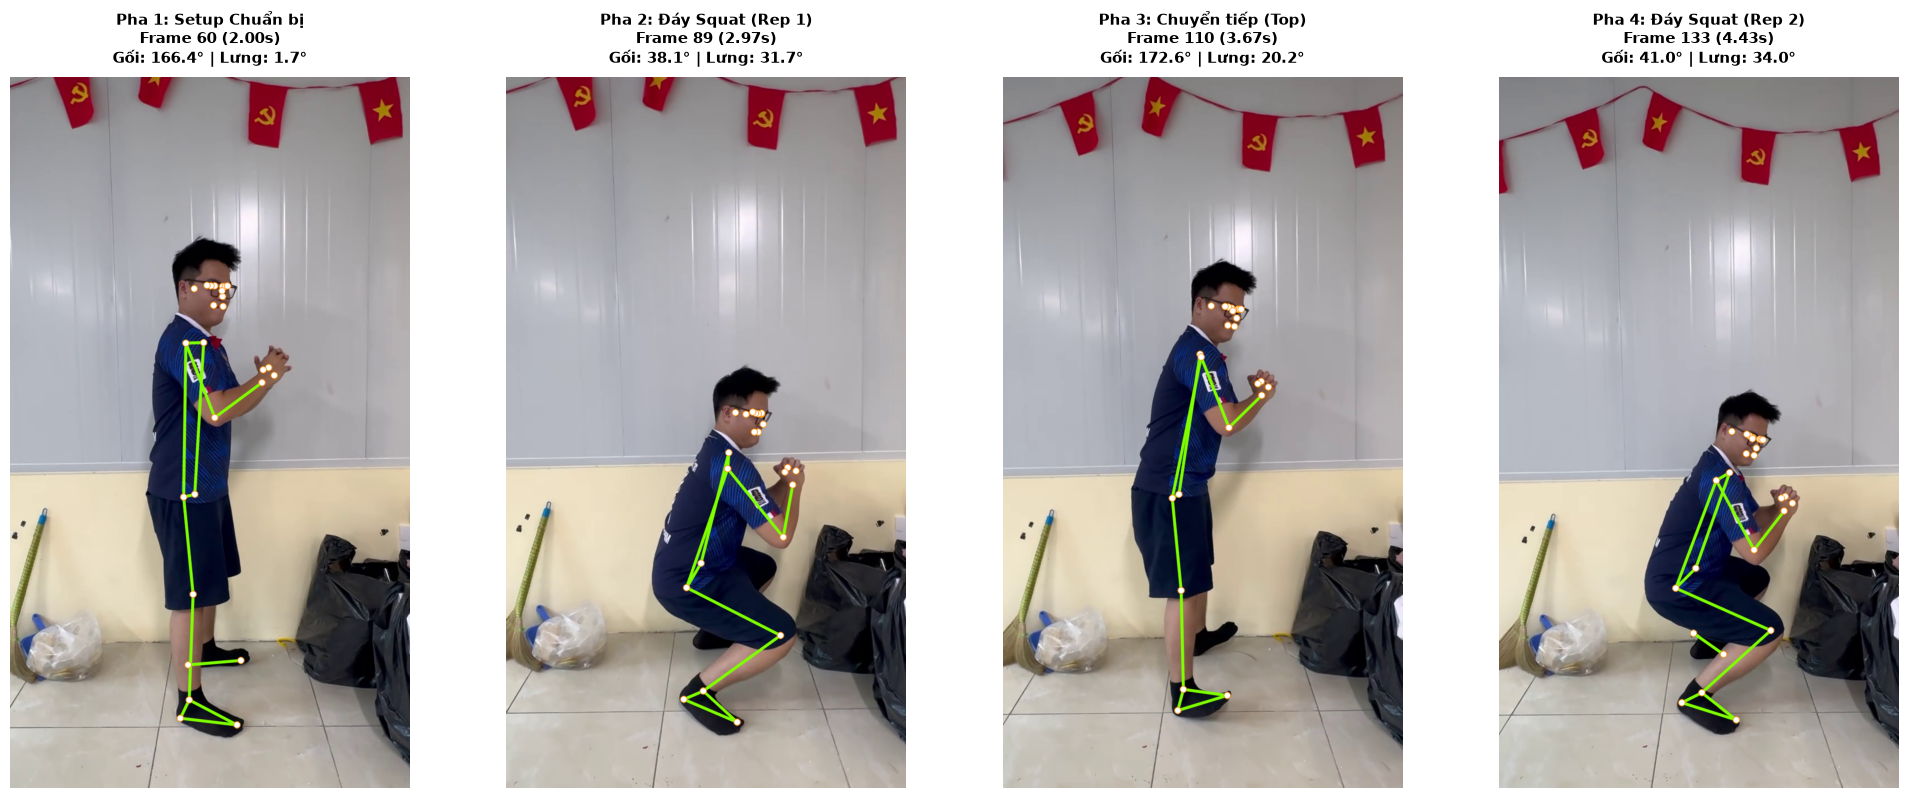

In [9]:
def calc_angle_3p(a, b, c):
    ba = a - b
    bc = c - b
    cos_val = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-6)
    return np.degrees(np.arccos(np.clip(cos_val, -1.0, 1.0)))

def calc_trunk_angle(shoulder, hip):
    v = shoulder - hip
    vertical = np.array([0, -1])
    cos_val = np.dot(v, vertical) / (np.linalg.norm(v) * np.linalg.norm(vertical) + 1e-6)
    return np.degrees(np.arccos(np.clip(cos_val, -1.0, 1.0)))

cap_user = cv2.VideoCapture(str(user_video_path))
key_frames = [60, 89, 110, 133]
key_titles = [
    'Pha 1: Setup Chuẩn bị',
    'Pha 2: Đáy Squat (Rep 1)',
    'Pha 3: Chuyển tiếp (Top)',
    'Pha 4: Đáy Squat (Rep 2)'
]

fig, axes = plt.subplots(1, 4, figsize=(20, 8))

for ax, f_idx, title in zip(axes, key_frames, key_titles):
    cap_user.set(cv2.CAP_PROP_POS_FRAMES, f_idx)
    ret, frame = cap_user.read()
    if ret and f_idx < len(user_result.frames):
        f_pose = user_result.frames[f_idx]
        annotated = engine.draw_skeleton(frame, f_pose.landmarks, thickness=3, radius=5)
        
        sh = f_pose.get_landmark(f'{dominant_side}_shoulder')
        hip = f_pose.get_landmark(f'{dominant_side}_hip')
        knee = f_pose.get_landmark(f'{dominant_side}_knee')
        ank = f_pose.get_landmark(f'{dominant_side}_ankle')
        
        p_sh = np.array([sh['x'], sh['y']])
        p_hip = np.array([hip['x'], hip['y']])
        p_knee = np.array([knee['x'], knee['y']])
        p_ank = np.array([ank['x'], ank['y']])
        
        k_ang = calc_angle_3p(p_hip, p_knee, p_ank)
        t_lean = calc_trunk_angle(p_sh, p_hip)
        
        rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
        ax.imshow(rgb)
        time_s = f_idx / user_result.fps
        ax.set_title(f'{title}\nFrame {f_idx} ({time_s:.2f}s)\nGối: {k_ang:.1f}° | Lưng: {t_lean:.1f}°', 
                     fontsize=11, fontweight='bold', pad=10)
        ax.axis('off')

cap_user.release()
plt.tight_layout()
plt.show()

## 10. Biểu đồ Quỹ đạo Góc Sinh cơ học (Kinematic Trajectories)
Đồ thị thể hiện sự biến thiên góc khớp xuyên suốt 178 frames (5.93 giây):
1. **Góc gập đầu gối (Knee Angle):** Quan sát trực quan 2 chu kỳ hạ - nâng và tốc độ chuyển động (Tempo).
2. **Góc nghiêng thân trên (Trunk Lean):** Đánh giá độ ổn định và góc gập của cột sống.

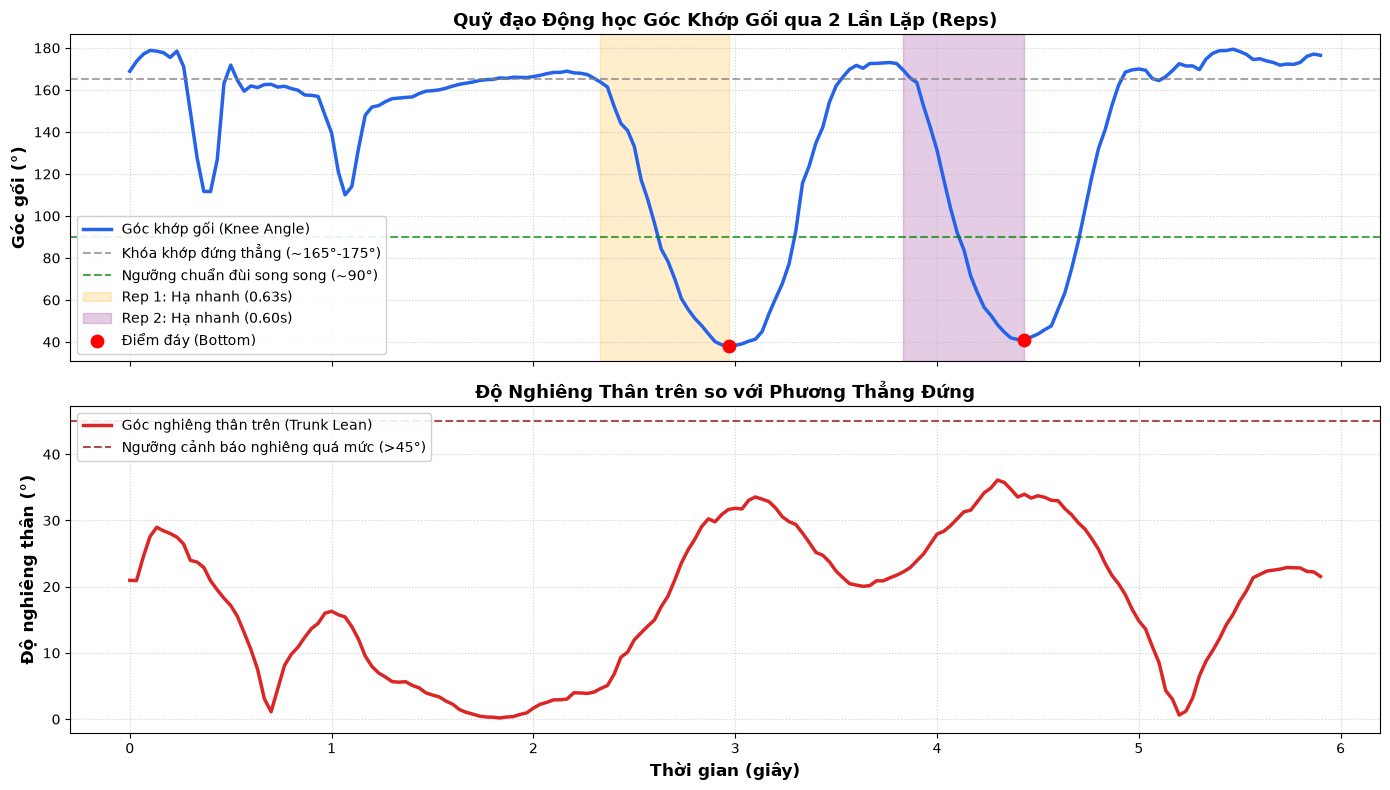

In [10]:
knee_angle_series = []
hip_angle_series = []
trunk_lean_series = []
time_series = []

for idx, f in enumerate(user_result.frames):
    t_sec = idx / user_result.fps
    time_series.append(t_sec)
    if not f.is_detected:
        knee_angle_series.append(np.nan)
        hip_angle_series.append(np.nan)
        trunk_lean_series.append(np.nan)
        continue
    
    sh = f.get_landmark(f'{dominant_side}_shoulder')
    hip = f.get_landmark(f'{dominant_side}_hip')
    knee = f.get_landmark(f'{dominant_side}_knee')
    ank = f.get_landmark(f'{dominant_side}_ankle')
    
    p_sh = np.array([sh['x'], sh['y']])
    p_hip = np.array([hip['x'], hip['y']])
    p_knee = np.array([knee['x'], knee['y']])
    p_ank = np.array([ank['x'], ank['y']])
    
    knee_angle_series.append(calc_angle_3p(p_hip, p_knee, p_ank))
    hip_angle_series.append(calc_angle_3p(p_sh, p_hip, p_knee))
    trunk_lean_series.append(calc_trunk_angle(p_sh, p_hip))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Đồ thị góc gối
ax1.plot(time_series, knee_angle_series, color='#2563EB', linewidth=2.5, label='Góc khớp gối (Knee Angle)')
ax1.axhline(y=165, color='gray', linestyle='--', alpha=0.7, label='Khóa khớp đứng thẳng (~165°-175°)')
ax1.axhline(y=90, color='green', linestyle='--', alpha=0.7, label='Ngưỡng chuẩn đùi song song (~90°)')
ax1.axvspan(2.33, 2.97, color='orange', alpha=0.2, label='Rep 1: Hạ nhanh (0.63s)')
ax1.axvspan(3.83, 4.43, color='purple', alpha=0.2, label='Rep 2: Hạ nhanh (0.60s)')
ax1.scatter([2.97, 4.43], [knee_angle_series[89], knee_angle_series[133]], color='red', s=80, zorder=5, label='Điểm đáy (Bottom)')
ax1.set_ylabel('Góc gối (°)', fontsize=12, fontweight='bold')
ax1.set_title('Quỹ đạo Động học Góc Khớp Gối qua 2 Lần Lặp (Reps)', fontsize=13, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower left', framealpha=0.9)

# Đồ thị góc nghiêng thân
ax2.plot(time_series, trunk_lean_series, color='#DC2626', linewidth=2.5, label='Góc nghiêng thân trên (Trunk Lean)')
ax2.axhline(y=45, color='darkred', linestyle='--', alpha=0.7, label='Ngưỡng cảnh báo nghiêng quá mức (>45°)')
ax2.set_ylabel('Độ nghiêng thân (°)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Thời gian (giây)', fontsize=12, fontweight='bold')
ax2.set_title('Độ Nghiêng Thân trên so với Phương Thẳng Đứng', fontsize=13, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper left', framealpha=0.9)

plt.tight_layout()
plt.show()

## 11. Báo cáo Đánh giá Lỗi Kỹ thuật Sinh cơ học (Biomechanical Form Diagnosis)
Dựa trên chuỗi tọa độ 33 khớp được bóc tách định lượng, hệ thống rút ra 5 tiêu chí chẩn đoán chuyên sâu:

| Tiêu chí | Đo đạc thực tế (`test_squat.mp4`) | Ngưỡng chuẩn an toàn | Đánh giá & Khuyến nghị |
| :--- | :--- | :--- | :--- |
| **1. Tốc độ hạ (Tempo)** | Rep 1: 0.63s \| Rep 2: 0.60s | 2.0s – 3.0s (Kiểm soát) | 🔴 **LỖI:** Thả rơi quá nhanh (*Dive-bombing*), tạo xung lực va đập lớn lên gân bánh chè. Cần hãm chậm cơ đùi trước. |
| **2. Độ sâu (Depth)** | Hông cao hơn gối ~85px (Đùi dốc xuống 15°-18°) | Nếp gấp hông ngang hoặc dưới gối | 🟡 **LỖI:** Chưa đạt chuẩn song song (*Half Squat*). Cơ mông và cơ đùi sau chưa được kích hoạt tối đa. |
| **3. Cổ chân & Gót chân** | Gối lao trước mũi chân 77.7px; Gót nhấc ~33px | Gót chân dính chặt sàn, chia đều lực | 🔴 **LỖI:** Nhấc gót chân (*Heel Rise*) do hạn chế độ gập cổ chân (*Dorsiflexion*), dồn lực lên mũi chân. |
| **4. Khóa hông (Lockout)** | Đỉnh giữa 2 rep chỉ đạt 150.1° | 170° – 180° (Duỗi thẳng hoàn toàn) | 🟡 **LỖI:** Chưa duỗi thẳng hoàn toàn khớp hông trước khi bắt đầu Rep 2. |
| **5. Tư thế lưng (Trunk)** | Góc nghiêng thân đáy: 31.8° – 33.7° | $\le 45^\circ$ so với phương đứng | 🟢 **TỐT:** Cột sống giữ độ nghiêng vừa phải, không bị gập lưng quá mức. |

In [11]:
# 1. Xuất file JSON dữ liệu tọa độ khớp của test_squat
out_user_json = project_root / 'data' / 'processed' / 'landmarks' / 'test_squat.json'
out_user_dict = {
    'video_name': user_video_path.name,
    'dominant_side': dominant_side,
    'fps': user_result.fps,
    'width': user_result.width,
    'height': user_result.height,
    'total_frames': user_result.total_frames,
    'detection_rate': user_result.detection_rate,
    'frames': [
        {
            'frame_idx': f.frame_idx,
            'timestamp_ms': f.timestamp_ms,
            'is_detected': f.is_detected,
            'landmarks': f.landmarks,
            'world_landmarks': f.world_landmarks
        }
        for f in user_result.frames
    ]
}

with open(out_user_json, 'w', encoding='utf-8') as f:
    json.dump(out_user_dict, f, indent=2, ensure_ascii=False)

# 2. Đóng gói video overlay có gắn khung xương
out_overlay_path = project_root / 'data' / 'outputs' / 'overlays' / 'test_squat_overlay.mp4'
out_overlay_path.parent.mkdir(parents=True, exist_ok=True)

cap_src = cv2.VideoCapture(str(user_video_path))
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
writer = cv2.VideoWriter(str(out_overlay_path), fourcc, user_result.fps, (user_result.width, user_result.height))

f_i = 0
while cap_src.isOpened():
    ret, frame = cap_src.read()
    if not ret or f_i >= len(user_result.frames):
        break
    f_pose = user_result.frames[f_i]
    if f_pose.is_detected:
        ann = engine.draw_skeleton(frame, f_pose.landmarks, thickness=3, radius=5)
        t_sec = f_i / user_result.fps
        cv2.putText(ann, f'Frame: {f_i:03d} | Time: {t_sec:.2f}s', (30, 50),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 255), 2, cv2.LINE_AA)
        cv2.putText(ann, f'Dominant: {dominant_side.upper()} | MediaPipe Heavy', (30, 95),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2, cv2.LINE_AA)
        writer.write(ann)
    else:
        writer.write(frame)
    f_i += 1

cap_src.release()
writer.release()

print(f'💾 Đã lưu JSON tọa độ chuỗi khớp tại: {out_user_json} ({out_user_json.stat().st_size / (1024*1024):.2f} MB)')
print(f'📹 Đã xuất video khung xương overlay tại: {out_overlay_path} ({out_overlay_path.stat().st_size / (1024*1024):.2f} MB)')
print('🎯 HOÀN TẤT BÀI THỰC NGHIỆM TRÊN VIDEO TEST_SQUAT!')

💾 Đã lưu JSON tọa độ chuỗi khớp tại: D:\Project\AI_Biomechanics_Coach\data\processed\landmarks\test_squat.json (3.11 MB)
📹 Đã xuất video khung xương overlay tại: D:\Project\AI_Biomechanics_Coach\data\outputs\overlays\test_squat_overlay.mp4 (4.77 MB)
🎯 HOÀN TẤT BÀI THỰC NGHIỆM TRÊN VIDEO TEST_SQUAT!
